# **Laboratorio 3: Intervalos de Confianza y Test de Hipótesis — Airbnb Nueva York**  
INF280 Estadística Computacional, UTFSM — Grupo 25  
Integrantes: José Flores, Sebastian Alcaide, Pedro Ortiz y Miguel Primera

### Declaración de uso de herramientas de IA
Se utilizó ChatGPT/Codex como apoyo para el análisis, el código y la preparación de los archivos. El equipo debe revisar y comprender cada línea de código y cada afirmación antes de entregar el trabajo.

### Ejecución
Ejecutar todas las celdas en orden. Los datos se descargan automáticamente desde Kaggle mediante `kagglehub`, como en la Entrega 2. No es necesario subir un CSV ni preparar una carpeta `data`.

Si falta alguna dependencia, instalarla con `pip install -r requirements.txt`. En Google Colab se puede ejecutar `%pip install -q kagglehub statsmodels` antes de las importaciones. NumPy, pandas, SciPy, Matplotlib y scikit-learn suelen estar disponibles en Colab.

In [20]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display, Markdown

# Mismo bootstrap de la Entrega 2. Las otras simulaciones usan semillas propias.
RANDOM_STATE = 2026
SEED_BOOTSTRAP = RANDOM_STATE
CONFIANZA = 0.954
ALPHA = 1 - CONFIANZA
B = 10_000
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})

DECIMALES_ESTIMACION = 4
DECIMALES_COMPARACION = 5
DECIMALES_PORCENTAJE = 2

def numero(valor, decimales=DECIMALES_ESTIMACION):
    return f"{valor:.{decimales}f}".replace('.', ',')

def porcentaje(probabilidad):
    return numero(100 * probabilidad, DECIMALES_PORCENTAJE) + ' %'

def entero(valor):
    return f'{valor:,}'.replace(',', '.')

def mostrar_tabla(tabla, decimales=DECIMALES_ESTIMACION,
                  columnas_porcentaje=(), columnas_pp=()):
    # Solo cambia la presentación; los cálculos conservan todos los decimales.
    vista = tabla.copy()
    for columna in vista.columns:
        if columna in columnas_porcentaje:
            vista[columna] = tabla[columna].map(porcentaje)
        elif columna in columnas_pp:
            vista[columna] = tabla[columna].map(
                lambda x: '—' if pd.isna(x) else numero(x, DECIMALES_PORCENTAJE))
        elif pd.api.types.is_float_dtype(tabla[columna]):
            vista[columna] = tabla[columna].map(lambda x: numero(x, decimales))
    display(vista)

print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | '
      f'pandas {pd.__version__} | Matplotlib {matplotlib.__version__} | '
      f'SciPy {scipy.__version__}')

Python 3.14.7 | NumPy 2.5.3 | pandas 3.0.5 | Matplotlib 3.11.2 | SciPy 1.18.1


In [21]:
# Descarga desde la misma fuente de Kaggle usada en la Entrega 2.
# Se fija la versión 1 para conservar exactamente los datos anteriores.
import kagglehub

RUTA_CSV = os.path.join(
    kagglehub.dataset_download('arianazmoudeh/airbnbopendata/versions/1'),
    'Airbnb_Open_Data.csv')
print('Archivo de datos:', RUTA_CSV)

Archivo de datos: C:\Users\Pepe\.cache\kagglehub\datasets\arianazmoudeh\airbnbopendata\versions\1\Airbnb_Open_Data.csv


In [22]:
# Limpieza del entregable anterior (solo lo necesario para este análisis:
# distrito y calificación)
df = pd.read_csv(RUTA_CSV, low_memory=False)
df = df.drop_duplicates()
df['neighbourhood group'] = df['neighbourhood group'].replace({
    'manhatan': 'Manhattan',
    'brookln': 'Brooklyn'
})
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

In [23]:
pares = df[['neighbourhood_group', 'review_rate_number']].dropna()
M = pares.loc[pares['neighbourhood_group'] == 'Manhattan', 'review_rate_number'].to_numpy()
K = pares.loc[pares['neighbourhood_group'] == 'Brooklyn', 'review_rate_number'].to_numpy()

# Mostrar conteos
print('Filas sin duplicados y limpiadas:', len(df), '| con distrito y nota:', len(pares))
print('Manhattan:', len(M), 'anuncios | Brooklyn:', len(K), 'anuncios')

n_m, n_b = len(M), len(K)
mu_m, mu_b = M.mean(), K.mean()
delta = mu_m - mu_b  # calcular ANTES de redondear
ee = np.array([M.std(ddof=1) / np.sqrt(n_m), K.std(ddof=1) / np.sqrt(n_b)])
ee_delta = np.sqrt((ee**2).sum())
nombres = ['Media Manhattan', 'Media Brooklyn', 'Diferencia M-B']
puntuales = np.array([mu_m, mu_b, delta])
mostrar_tabla(pd.DataFrame({'n': [n_m, n_b], 'media': [mu_m, mu_b], 'EE': ee},
                     index=['Manhattan', 'Brooklyn']))
print('Filas sin duplicados:', len(df), '| Pares completos:', len(pares))
print('Diferencia M-B:', numero(delta, 7), '| EE clásico:', numero(ee_delta, 7))

Filas sin duplicados y limpiadas: 102058 | con distrito y nota: 101712
Manhattan: 43418 anuncios | Brooklyn: 41515 anuncios


,n,media,EE
Manhattan,43418,"3,2765","0,0062"
Brooklyn,41515,"3,2585","0,0064"


Filas sin duplicados: 102058 | Pares completos: 101712
Diferencia M-B: 0,0180605 | EE clásico: 0,0088750


## 1. Parámetros de interés y conexión con las entregas anteriores

**Pregunta de investigación:** ¿qué tan grande es la diferencia de calificación media entre Manhattan y Brooklyn y qué tan precisa es su estimación?

En la Entrega 1 el ANOVA aportó evidencia contra la igualdad de las medias de los cinco distritos, sin identificar por sí solo un par diferente. En la Entrega 2 elegimos Manhattan y Brooklyn por sus tamaños muestrales, sin seleccionar las medias más extremas. Conservamos la pregunta, las variables, la limpieza y el procedimiento bootstrap de la versión entregada.

Los parámetros son $\mu_M$, la media poblacional de Manhattan, y $\mu_B$, la media poblacional de Brooklyn. El contraste derivado es $\Delta=\mu_M-\mu_B$, estimado mediante la diferencia de medias muestrales.

La unidad de análisis es **un anuncio**, con igual peso en el promedio. Las notas toman valores de 1 a 5 y se tratan numéricamente, como en E2. Usamos pares completos de `neighbourhood_group` y `review_rate_number`, sin imputar notas. La fuente es [Airbnb Open Data, arianazmoudeh, Kaggle](https://www.kaggle.com/datasets/arianazmoudeh/airbnbopendata). La versión 1 coincide con los datos utilizados en E2.

La inferencia requiere observaciones independientes y una selección adecuada para la población objetivo. Desconocemos la representatividad del dataset. Eliminar duplicados no garantiza independencia por anfitrión.

## 2. Intervalos de confianza y comprobación de resultados E2
### 2.1 Bootstrap percentil al 95,4 %
Los parámetros son $\mu_M$, $\mu_B$ y $\Delta=\mu_M-\mu_B$. No suponemos conocidas las varianzas poblacionales. Reproducimos la función propia de E2 con **10.000 remuestras y semilla 2026**, remuestreando independientemente dentro de cada distrito y conservando sus tamaños originales. La versión entregada no guardaba las réplicas en una celda de datos, por lo que se regeneran con el mismo algoritmo, semilla y CSV. No se sustituye el bootstrap por una aproximación normal.

Con $\alpha=0,046$, el IC percentil usa los cuantiles **0,023 y 0,977** de cada columna de réplicas. `np.quantile(..., method='linear')` interpola entre estadísticos ordenados. El margen de error pedido es el **semiancho** $(U-L)/2$, aunque el intervalo no sea perfectamente simétrico respecto de la estimación original.

Los tres IC son marginales por parámetro; no se atribuye cobertura conjunta del 95,4 %.

,estimacion,limite_inferior,limite_superior,ancho,semiancho,EE_bootstrap
Media Manhattan,"3,2765213","3,2643143","3,2890051","0,0246908","0,0123454","0,0062307"
Media Brooklyn,"3,2584608","3,2459111","3,2709629","0,0250517","0,0125259","0,0063009"
Diferencia M-B,"0,0180605","0,0006385","0,0357323","0,0350938","0,0175469","0,0088290"


EE bootstrap a cinco decimales: ['0,00623', '0,00630', '0,00883']


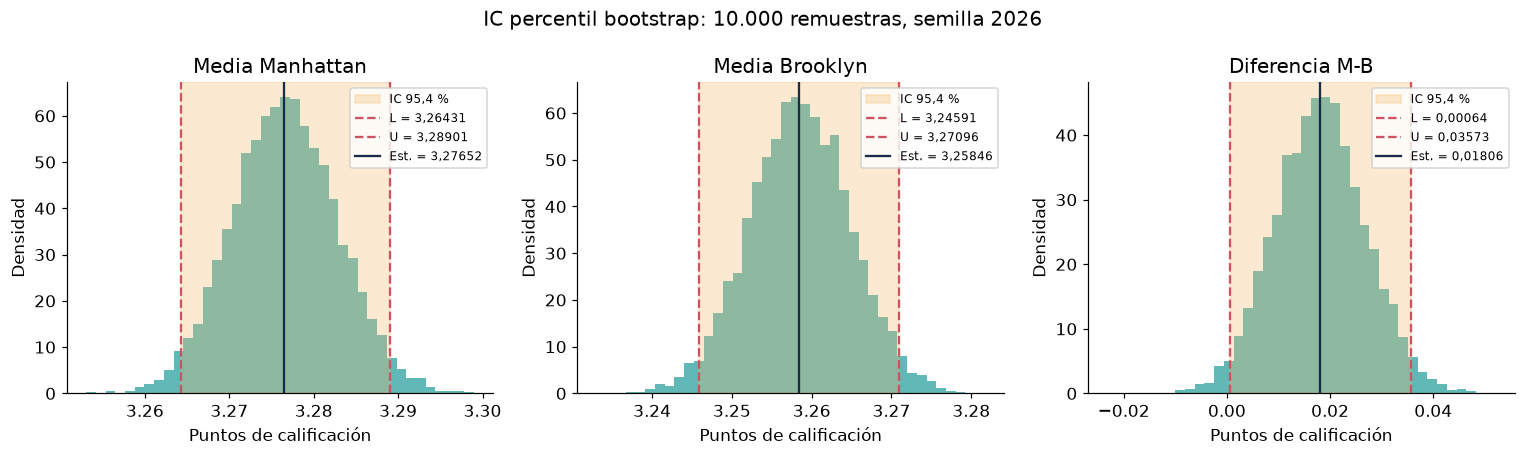

In [24]:
def bootstrap(x, y, B, rng):
    res = np.empty((B, 3))
    for b in range(B):
        xb = x[rng.integers(0, len(x), len(x))]
        yb = y[rng.integers(0, len(y), len(y))]
        res[b] = xb.mean(), yb.mean(), xb.mean() - yb.mean()
    return res

boot = bootstrap(M, K, B, np.random.default_rng(SEED_BOOTSTRAP))
limites = np.quantile(boot, [ALPHA / 2, 1 - ALPHA / 2], axis=0, method='linear')
L, U = limites
margen = (U - L) / 2
tabla_ic = pd.DataFrame({'estimacion': puntuales, 'limite_inferior': L,
    'limite_superior': U, 'ancho': U-L, 'semiancho': margen,
    'EE_bootstrap': boot.std(axis=0, ddof=1)}, index=nombres)
mostrar_tabla(tabla_ic, 7)
print('EE bootstrap a cinco decimales:', [numero(x, 5) for x in boot.std(axis=0, ddof=1)])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for j, ax in enumerate(axes):
    ax.hist(boot[:, j], bins=40, density=True, color='#1c9c99', alpha=.7)
    ax.axvspan(L[j], U[j], color='#f2ba68', alpha=.3, label='IC 95,4 %')
    ax.axvline(L[j], color='#ce5361', ls='--', label=f'L = {numero(L[j],5)}')
    ax.axvline(U[j], color='#ce5361', ls='--', label=f'U = {numero(U[j],5)}')
    ax.axvline(puntuales[j], color='#182b49', label=f'Est. = {numero(puntuales[j],5)}')
    ax.set(title=nombres[j], xlabel='Puntos de calificación', ylabel='Densidad')
    ax.legend(fontsize=8)
fig.suptitle('IC percentil bootstrap: 10.000 remuestras, semilla 2026')
fig.tight_layout()
plt.show()

In [25]:
display(Markdown(f"""El IC de la diferencia es **[{numero(L[2],5)}, {numero(U[2],5)}] puntos**,
con semiancho **{numero(margen[2],5)}**. El límite inferior es positivo y está próximo a cero.
El intervalo es informativo sobre la magnitud: acota la diferencia a pocas centésimas en una
escala de 1 a 5. La precisión absoluta es alta, aunque el semiancho sigue siendo grande
respecto de la diferencia observada de {numero(delta,5)}. La exclusión de cero es marginal y
depende de los supuestos y del error numérico del bootstrap. No equivale a una mejora
importante para quien elige alojamiento. El 95,4 % describe la cobertura nominal del
procedimiento bajo muestreo repetido, no una probabilidad posterior del parámetro."""))

El IC de la diferencia es **[0,00064, 0,03573] puntos**,
con semiancho **0,01755**. El límite inferior es positivo y está próximo a cero.
El intervalo es informativo sobre la magnitud: acota la diferencia a pocas centésimas en una
escala de 1 a 5. La precisión absoluta es alta, aunque el semiancho sigue siendo grande
respecto de la diferencia observada de 0,01806. La exclusión de cero es marginal y
depende de los supuestos y del error numérico del bootstrap. No equivale a una mejora
importante para quien elige alojamiento. El 95,4 % describe la cobertura nominal del
procedimiento bajo muestreo repetido, no una probabilidad posterior del parámetro.

### 2.2 Reducir el margen en un 55 % mediante más datos
Una reducción **en 55 %** deja $m_{nuevo}=0,45m_{actual}$. Para una media con varianza estable y observaciones independientes, $EE=s/\sqrt n$ y, a confianza fija y con distribución aproximadamente normal del estimador, $m\approx c\,EE$. Entonces
$$\frac{m_{nuevo}}{m_{actual}}\approx\sqrt{\frac{n}{n_{nuevo}}}=0,45,
\qquad n_{nuevo}\approx\frac{n}{0,45^2}=4,93827\,n.$$
Para $\Delta$, se aumentan **ambas muestras por ese mismo factor**, conservando aproximadamente la proporción entre distritos: $EE(\hat\Delta)=\sqrt{s_M^2/n_M+s_B^2/n_B}$. Escalar solo el total sin fijar su reparto no determina el nuevo margen. La fila de la diferencia no representa una tercera muestra y no debe sumarse a las anteriores.

In [26]:
fraccion = 0.45
factor = 1 / fraccion**2
nuevo_m, nuevo_b = np.ceil(np.array([n_m, n_b]) * factor).astype(int)
tabla_n = pd.DataFrame({
    'n_actual': [n_m, n_b, n_m+n_b],
    'n_objetivo_aprox': [nuevo_m, nuevo_b, nuevo_m+nuevo_b],
    'adicionales_aprox': [nuevo_m-n_m, nuevo_b-n_b, nuevo_m+nuevo_b-n_m-n_b],
    'semiancho_objetivo': fraccion*margen}, index=nombres)
mostrar_tabla(tabla_n, 7)
print('Factor de tamaño:', numero(factor, 6))

,n_actual,n_objetivo_aprox,adicionales_aprox,semiancho_objetivo
Media Manhattan,43418,214410,170992,"0,0055554"
Media Brooklyn,41515,205013,163498,"0,0056366"
Diferencia M-B,84933,419423,334490,"0,0078961"


Factor de tamaño: 4,938272


Esta es una proyección, no una garantía. Puede fallar con dependencia entre anuncios, cambios en la distribución de notas o en la selección, tamaños efectivos menores, cuantiles inestables o muestras pequeñas. Si la población fuese finita y se muestreara sin reemplazo una fracción importante, habría que considerar la corrección por población finita. Desconocemos ese marco poblacional. Aumentar filas con el mismo sesgo tampoco elimina ese sesgo.

### 2.3 Reducir el margen cambiando la confianza
Conservamos exactamente los datos y las 10.000 réplicas. Buscamos el intervalo central percentil cuyo semiancho esté más próximo a $0,45m$. Exploramos niveles de confianza entre 0,01 % y 99,99 %, en pasos de **0,01 puntos porcentuales**. Reportamos un resultado por parámetro porque sus distribuciones empíricas difieren. La cuadrícula, el número finito de réplicas y los empates impiden garantizar una reducción exacta.

In [27]:
confianzas = np.arange(1, 10000) / 10000
filas = []
for j, nombre in enumerate(nombres):
    q = np.quantile(boot[:, j], [(1-confianzas)/2, (1+confianzas)/2], method='linear')
    margenes = (q[1]-q[0])/2
    i = np.argmin(np.abs(margenes - fraccion*margen[j]))
    filas.append([nombre, confianzas[i], 1-confianzas[i], q[0,i], q[1,i],
                  margenes[i], 1-margenes[i]/margen[j]])
tabla_conf = pd.DataFrame(filas, columns=['parametro', 'confianza', 'alpha',
    'L', 'U', 'semiancho', 'reduccion']).set_index('parametro')
mostrar_tabla(tabla_conf, 7)

,confianza,alpha,L,U,semiancho,reduccion
parametro,,,,,,
Media Manhattan,"0,6268000","0,3732000","3,2710166","3,2821223","0,0055528","0,5502087"
Media Brooklyn,"0,6316000","0,3684000","3,2528965","3,2641696","0,0056365","0,5500100"
Diferencia M-B,"0,6328000","0,3672000","0,0101524","0,0259446","0,0078961","0,5499997"


**Comparación de estrategias.** Más datos independientes y pertinentes reducen la variabilidad de la estimación manteniendo la cobertura nominal del 95,4 %. Bajar la confianza estrecha el intervalo a costa de aumentar α y reducir su cobertura, sin mejorar la precisión del estimador ni su error estándar. Preferimos mantener el nivel y obtener más información si una decisión realmente requiere mayor precisión. En este problema la diferencia ya es muy pequeña y no se justifica reunir casi cinco veces la muestra solo para destacar una diferencia mínima. Lo más útil es comunicar su magnitud y las limitaciones de selección. Los niveles explorados aquí son un ejercicio de la pauta, **no reemplazan α en los tests siguientes**.

## 3. Bondad de ajuste del modelo de la Entrega 2
### 3.1 Elección y problema de calibración
E2 modeló cada nota mediante una distribución **categórica sobre 1, 2, 3, 4, 5**, con probabilidades empíricas por distrito. Los conteos de una muestra siguen una multinomial bajo independencia. No se asumió que las notas individuales fueran normales.

| Prueba investigada | Características y decisión |
|---|---|
| Kolmogorov-Smirnov | Compara funciones de distribución acumulada. Los valores críticos usuales suponen una distribución continua y completamente especificada. Aquí hay solo cinco valores y muchos empates. Una adaptación discreta y con parámetros estimados exige otra calibración. |
| Anderson-Darling | Da más peso a las colas. Su calibración depende de la distribución evaluada. Las tablas habituales para distribuciones continuas no se pueden aplicar directamente a estas notas categóricas. |
| Pearson / Chi-cuadrado | Compara conteos observados y esperados. Es natural para cinco categorías y muestras grandes. Hay que tratar correctamente las probabilidades estimadas. Elegimos su estadístico, con calibración por simulación. |

Si estimáramos las cinco probabilidades con **todos** los datos y luego usáramos esos mismos datos para evaluar ajuste, $E_k=O_k$, el estadístico sería cero por construcción. Hay cuatro probabilidades libres y $5-1-4=0$ grados de libertad: un p-value convencional con cuatro grados de libertad sería inválido. El modelo categórico sin restricciones es saturado para esa distribución marginal.

Para obtener una comprobación que no sea circular, dividimos aleatoriamente **cada distrito** en dos mitades disjuntas (semilla 2028): ajuste y validación. Estimamos las probabilidades en ajuste y comparamos los conteos de validación con lo esperado a partir de ellas. La pregunta comprobable es si **ambas mitades son compatibles con una misma distribución categórica fija**. Es una validación interna del modelo E2, no una validación externa de sus probabilidades finales ni una prueba de representatividad o independencia.

### 3.2 Prueba de Pearson con calibración Monte Carlo
Por distrito, $H_0:p_k^{ajuste}=p_k^{validación}$ para todo $k$ y $H_1$: al menos una probabilidad difiere. Usamos
$$D=\sum_{k=1}^5\frac{(O_{v,k}-n_v\hat p_{a,k})^2}{n_v\hat p_{a,k}}.$$
Como $\hat p_a$ se estima y su incertidumbre no es despreciable frente a una mitad de tamaño parecido, **no** comparamos D con una $\chi^2_4$ convencional. Bajo $H_0$, estimamos la probabilidad común mediante los conteos combinados y simulamos **10.000 pares independientes** de conteos multinomiales con los tamaños de ambas mitades. En cada réplica volvemos a estimar $\hat p_a^*$ y recalculamos $D^*$. Así se incorpora el paso de estimación. Este bootstrap paramétrico usa probabilidades comunes estimadas, por lo que su calibración es aproximada.

El p-value es $(1+\#\{D^*\ge D\})/(R+1)$, con semilla 2029. Trabajamos con **α = 0,05 por distrito**, fijado antes de ver la partición. Un α mayor rechaza más fácilmente el ajuste y aumenta el riesgo de rechazo falso. Uno menor hace lo contrario y puede ocultar desajustes. El 5 % ofrece un criterio exploratorio convencional, pero no valida independencia ni permite afirmar ajuste exacto. Los dos resultados se interpretan por distrito, sin atribuir un control familiar del 5 %.

,n_ajuste,n_validacion,D,p_value,min_esperado,rechaza_5pct
Manhattan,"21709,0000000","21709,0000000","2,1667316","0,8996100","2007,0000000",False
Brooklyn,"20758,0000000","20757,0000000","9,3589126","0,3201680","2011,9030735",False


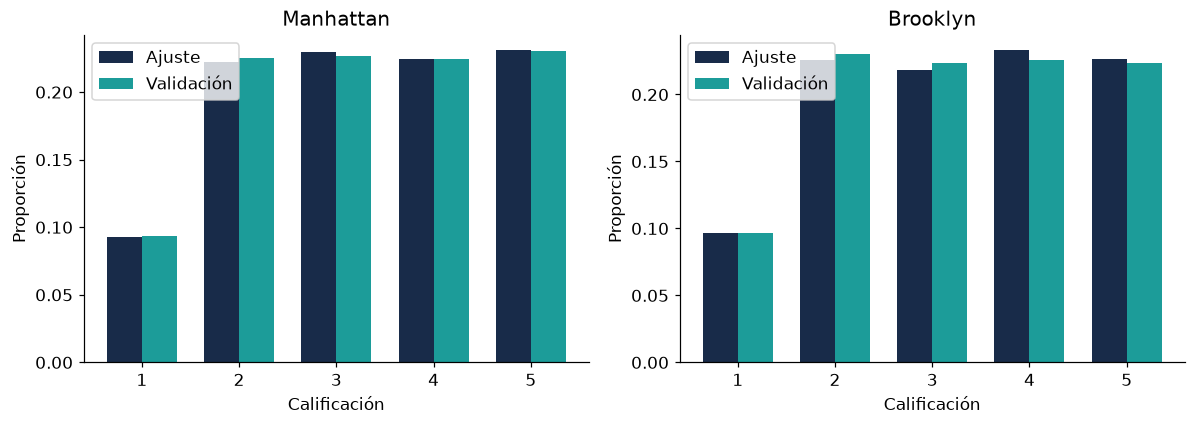

In [28]:
def conteos(x):
    return np.bincount(x.astype(int), minlength=6)[1:6]

def bondad_validacion(x, rng_particion, rng_sim, R=10_000):
    ajuste, validacion = np.array_split(rng_particion.permutation(x), 2)
    ca, cv = conteos(ajuste), conteos(validacion)
    na, nv = len(ajuste), len(validacion)
    p_ajuste = ca/na
    esperado = nv*p_ajuste
    assert (esperado >= 5).all()
    D = ((cv-esperado)**2/esperado).sum()
    p_comun = (ca+cv)/(na+nv)
    # Repetir ambos pasos: estimar probabilidades y evaluar otra muestra.
    ajuste_sim = rng_sim.multinomial(na, p_comun, size=R)
    validacion_sim = rng_sim.multinomial(nv, p_comun, size=R)
    esperado_sim = nv*ajuste_sim/na
    assert (esperado_sim > 0).all()
    D_sim = ((validacion_sim-esperado_sim)**2/esperado_sim).sum(axis=1)
    p_value = (1+(D_sim >= D).sum())/(R+1)
    return {'n_ajuste': na, 'n_validacion': nv, 'D': D, 'p_value': p_value,
            'min_esperado': esperado.min()}, ca/na, cv/nv, D_sim

rng_particion = np.random.default_rng(2028)
rng_sim = np.random.default_rng(2029)
gof, detalle_gof = {}, {}
for nombre, x in [('Manhattan', M), ('Brooklyn', K)]:
    gof[nombre], pa, pv, ds = bondad_validacion(x, rng_particion, rng_sim)
    detalle_gof[nombre] = (pa, pv, ds)
tabla_gof = pd.DataFrame(gof).T
tabla_gof['rechaza_5pct'] = tabla_gof.p_value < 0.05
mostrar_tabla(tabla_gof, 7)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nombre in zip(axes, gof):
    pa, pv, _ = detalle_gof[nombre]
    ax.bar(np.arange(1,6)-.18, pa, width=.36, label='Ajuste', color='#182b49')
    ax.bar(np.arange(1,6)+.18, pv, width=.36, label='Validación', color='#1c9c99')
    ax.set(title=nombre, xlabel='Calificación', ylabel='Proporción', xticks=np.arange(1,6))
    ax.legend()
fig.tight_layout()
plt.show()

In [29]:
display(Markdown(f"""Los p-values son **{numero(gof['Manhattan']['p_value'],4)}** para Manhattan
y **{numero(gof['Brooklyn']['p_value'],4)}** para Brooklyn. No rechazamos la compatibilidad
entre las mitades al 5 % en ninguno de los distritos. La incertidumbre Monte Carlo de
cada p-value tiene EE de aproximadamente
{numero(np.sqrt(gof['Manhattan']['p_value']*(1-gof['Manhattan']['p_value'])/10000),4)} y
{numero(np.sqrt(gof['Brooklyn']['p_value']*(1-gof['Brooklyn']['p_value'])/10000),4)}.
Las decisiones quedan lejos del umbral. **No rechazar no demuestra que el modelo sea correcto.**
Al partir aleatoriamente un mismo dataset, esta comprobación tiene un alcance limitado:
no detecta por sí sola sesgos comunes a ambas mitades. La pauta pide evaluar otra distribución
si se rechaza la inicial; esa condición no se activa aquí. No inventamos una normalidad de
las notas para sustituir el modelo realmente usado en E2.

Esto es coherente con los IC: no se detecta inestabilidad marginal entre mitades y las
medias disponen de muestras grandes. Pero esta prueba no demuestra la cobertura de los
IC ni sus supuestos de independencia. Los IC percentiles remuestrean las notas observadas
y no necesitan que las notas individuales sigan una normal."""))

Los p-values son **0,8996** para Manhattan
y **0,3202** para Brooklyn. No rechazamos la compatibilidad
entre las mitades al 5 % en ninguno de los distritos. La incertidumbre Monte Carlo de
cada p-value tiene EE de aproximadamente
0,0030 y
0,0047.
Las decisiones quedan lejos del umbral. **No rechazar no demuestra que el modelo sea correcto.**
Al partir aleatoriamente un mismo dataset, esta comprobación tiene un alcance limitado:
no detecta por sí sola sesgos comunes a ambas mitades. La pauta pide evaluar otra distribución
si se rechaza la inicial; esa condición no se activa aquí. No inventamos una normalidad de
las notas para sustituir el modelo realmente usado en E2.

Esto es coherente con los IC: no se detecta inestabilidad marginal entre mitades y las
medias disponen de muestras grandes. Pero esta prueba no demuestra la cobertura de los
IC ni sus supuestos de independencia. Los IC percentiles remuestrean las notas observadas
y no necesitan que las notas individuales sigan una normal.

## 4. Comparación con estadísticos
### 4.1 Test de medias: Manhattan frente a Brooklyn
**Criterio de grupos.** Usamos el distrito, conservando la selección de E2 por tamaño muestral. Contraste bilateral, porque interesa cualquier diferencia, sin fijar la dirección usando los resultados.

**Hipótesis:** $H_0:\mu_M=\mu_B$ frente a $H_1:\mu_M\ne\mu_B$.

**Varianzas desconocidas.** Elegimos Welch, que no exige igualdad de varianzas entre distritos:
$$T_0=\frac{\bar Y_M-\bar Y_B}{\sqrt{s_M^2/n_M+s_B^2/n_B}},\qquad
T_0\overset{H_0}{\approx}t_\nu,$$
$$\nu=\frac{(s_M^2/n_M+s_B^2/n_B)^2}{(s_M^2/n_M)^2/(n_M-1)+(s_B^2/n_B)^2/(n_B-1)}.$$

**Nivel y región crítica:** $\alpha=0,046$, coherente con la confianza 95,4 % de la primera sección. Rechazamos si $|T_0|\ge t_{\nu,1-\alpha/2}$. Se fija este nivel antes del contraste.

**Supuestos:** independencia dentro de cada grupo y entre grupos, muestras pertinentes para la población objetivo y varianzas finitas. Las notas discretas no son normales. Con más de 40.000 anuncios por distrito y notas acotadas, la aproximación de las medias por el TCL es razonable bajo independencia. La distribución t de Welch y sus grados de libertad son aproximados, no un resultado exacto para estas notas.

,T,gl_aprox,p_value,alpha,critico_positivo,rechaza
0,"2,03497632","84734,14218784","0,04185636","0,04600000","1,99542264",True


IC de Welch al 95,4 %: ['0,0003510', '0,0357699']


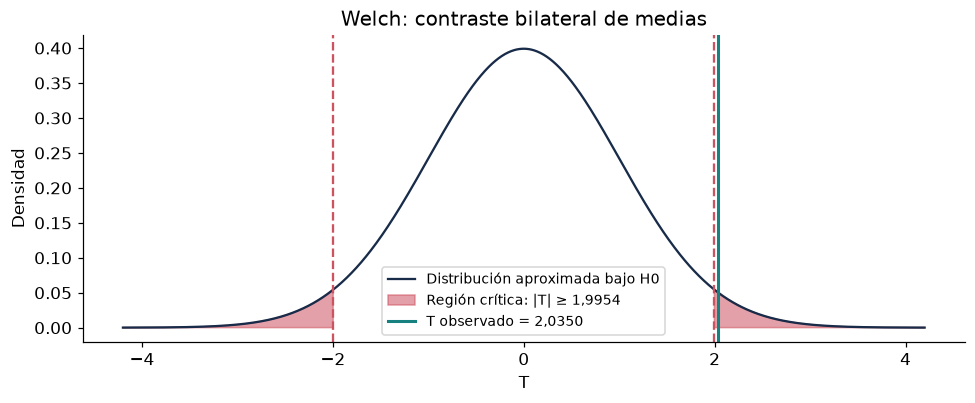

In [30]:
v_m, v_b = M.var(ddof=1), K.var(ddof=1)
grados = (v_m/n_m+v_b/n_b)**2 / ((v_m/n_m)**2/(n_m-1)+(v_b/n_b)**2/(n_b-1))
t0 = delta/ee_delta
p_welch = 2*stats.t.sf(abs(t0), grados)
crit_t = stats.t.ppf(1-ALPHA/2, grados)
ic_welch = delta + np.array([-1, 1])*crit_t*ee_delta
mostrar_tabla(pd.DataFrame({'T': [t0], 'gl_aprox': [grados], 'p_value': [p_welch],
    'alpha': [ALPHA], 'critico_positivo': [crit_t], 'rechaza': [p_welch < ALPHA]}), 8)
print('IC de Welch al 95,4 %:', [numero(x, 7) for x in ic_welch])

def grafico_bilateral(dist, observado, critico, titulo, simbolo):
    xx = np.linspace(-4.2, 4.2, 1000)
    yy = dist.pdf(xx)
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(xx, yy, color='#182b49', label='Distribución aproximada bajo H0')
    ax.fill_between(xx, yy, where=(np.abs(xx) >= critico), color='#ce5361', alpha=.55,
                    label=f'Región crítica: |{simbolo}| ≥ {numero(critico,4)}')
    ax.axvline(observado, color='#16817f', lw=2, label=f'{simbolo} observado = {numero(observado,4)}')
    ax.axvline(-critico, color='#ce5361', ls='--')
    ax.axvline(critico, color='#ce5361', ls='--')
    ax.set(title=titulo, xlabel=simbolo, ylabel='Densidad')
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

grafico_bilateral(stats.t(df=grados), t0, crit_t, 'Welch: contraste bilateral de medias', 'T')

In [31]:
display(Markdown(f"""**Decisión:** rechazamos H0 con α = {numero(ALPHA,3)} porque
p = **{numero(p_welch,6)}**. Bajo H0 y los supuestos, la probabilidad de obtener un estadístico
al menos tan extremo en cualquiera de las dos colas es aproximadamente {porcentaje(p_welch)}.
Esto no es la probabilidad de que H0 sea verdadera. Hay evidencia limitada de una diferencia
de medias: {numero(delta,5)} puntos a favor de Manhattan. El resultado está cerca del umbral y
su relevancia práctica es pequeña. El IC de Welch y el percentil bootstrap excluyen cero
por poco, de manera consistente. Son procedimientos diferentes y no tienen que coincidir exactamente."""))

**Decisión:** rechazamos H0 con α = 0,046 porque
p = **0,041856**. Bajo H0 y los supuestos, la probabilidad de obtener un estadístico
al menos tan extremo en cualquiera de las dos colas es aproximadamente 4,19 %.
Esto no es la probabilidad de que H0 sea verdadera. Hay evidencia limitada de una diferencia
de medias: 0,01806 puntos a favor de Manhattan. El resultado está cerca del umbral y
su relevancia práctica es pequeña. El IC de Welch y el percentil bootstrap excluyen cero
por poco, de manera consistente. Son procedimientos diferentes y no tienen que coincidir exactamente.

**Errores posibles.** Tipo I: concluir que las medias poblacionales de Manhattan y Brooklyn difieren cuando son iguales. Tipo II: no detectar una diferencia real entre esas medias. Para una recomendación de alojamiento consideramos más grave el tipo I, porque podría promover una superioridad sin fundamento. El tipo II también importa, aunque omitir una diferencia de pocas centésimas tendría menor impacto práctico. No hemos estimado la probabilidad de error tipo II ni la potencia.

### 4.2 IC con varianzas conocidas frente a desconocidas
Si las varianzas poblacionales fueran conocidas, un IC normal para la diferencia sería
$$\hat\Delta\ \pm\ z_{1-\alpha/2}\sqrt{\frac{\sigma_M^2}{n_M}+\frac{\sigma_B^2}{n_B}}.$$
Es exacto para medias de poblaciones normales independientes, y aproximado por TCL en este contexto de notas acotadas. Con varianzas desconocidas usamos
$$\hat\Delta\ \pm\ t_{\nu,1-\alpha/2}\sqrt{\frac{s_M^2}{n_M}+\frac{s_B^2}{n_B}}.$$
El cuantil t considera la estimación de las varianzas y es algo mayor que el cuantil z para el mismo nivel. Aquí los grados de libertad son muy grandes y ambos cuantiles casi coinciden. Sin conocer las $\sigma^2$ reales no se puede asegurar numéricamente cuánto cambiaría el ancho ni que el IC conocido sea siempre más estrecho en una muestra concreta. No sustituimos $\sigma$ por $s$ y lo llamamos varianza conocida. Estas fórmulas no reemplazan al IC percentil solicitado, que ya calculamos.

In [32]:
print('Cuantil z:', numero(stats.norm.ppf(1-ALPHA/2), 8))
print('Cuantil t de Welch:', numero(crit_t, 8))

Cuantil z: 1,99539331
Cuantil t de Welch: 1,99542264


### 4.3 Segundo test: proporción de calificaciones altas
Definimos **nota alta = 4 o 5**, las dos categorías superiores de la escala, como complemento interpretable de la media. El umbral se justifica por la escala y no se ajusta para buscar significancia. Se refiere a anuncios, no a proporción de reseñas ni satisfacción individual de huéspedes.

**Hipótesis:** $H_0:p_M=p_B$ frente a $H_1:p_M\ne p_B$, donde $p_g=P(Y\ge4\mid g)$.

**Estadístico y distribución bajo H0: **
$$Z_0=\frac{\hat p_M-\hat p_B}{\sqrt{\hat p(1-\hat p)(1/n_M+1/n_B)}},\qquad
\hat p=\frac{x_M+x_B}{n_M+n_B},\qquad Z_0\overset{H_0}{\approx}N(0,1).$$

**Región crítica:** $|Z_0|\ge z_{1-\alpha/2}$ con **α = 0,046**, fijado como en el contraste anterior.

**Supuestos:** anuncios independientes, grupos disjuntos y conteos esperados de notas altas y no altas suficientemente grandes en ambos grupos. La aproximación normal es apropiada con estos conteos. Este contraste compara probabilidades de superar un umbral, por lo que es distinto de comparar medias.

,notas_4_o_5,n,proporcion
Manhattan,19762,43418,"0,4551568"
Brooklyn,18868,41515,"0,4544863"


Diferencia en puntos porcentuales: 0,067052
Z: 0,196164 | p-value: 0,844482 | α: 0,046


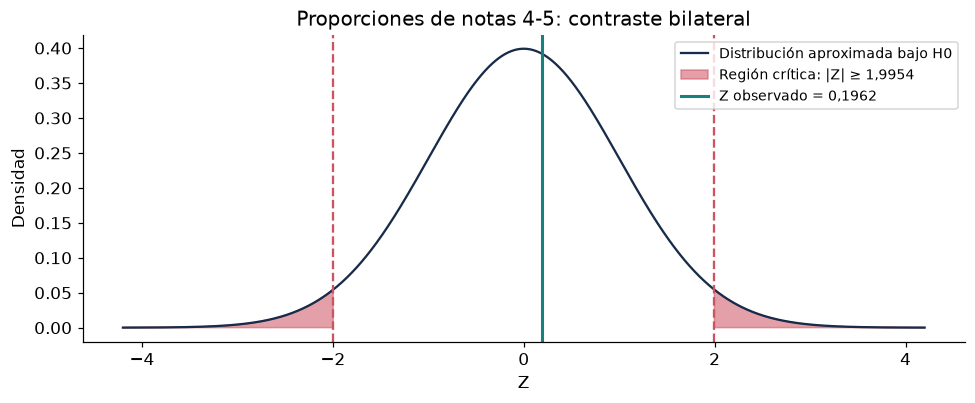

In [33]:
x_m, x_b = (M >= 4).sum(), (K >= 4).sum()
prop_m, prop_b = x_m/n_m, x_b/n_b
prop_comun = (x_m+x_b)/(n_m+n_b)
esperados_prop = np.outer([n_m,n_b], [prop_comun,1-prop_comun])
assert (esperados_prop >= 5).all()
ee_prop_nulo = np.sqrt(prop_comun*(1-prop_comun)*(1/n_m+1/n_b))
z0 = (prop_m-prop_b)/ee_prop_nulo
p_prop = 2*stats.norm.sf(abs(z0))
crit_z = stats.norm.ppf(1-ALPHA/2)
mostrar_tabla(pd.DataFrame({'notas_4_o_5': [x_m,x_b], 'n': [n_m,n_b],
    'proporcion': [prop_m,prop_b]}, index=['Manhattan','Brooklyn']), 7)
print('Diferencia en puntos porcentuales:', numero(100*(prop_m-prop_b),6))
print('Z:', numero(z0,6), '| p-value:', numero(p_prop,6), '| α:', numero(ALPHA,3))
grafico_bilateral(stats.norm(), z0, crit_z, 'Proporciones de notas 4-5: contraste bilateral', 'Z')

In [34]:
display(Markdown(f"""**Decisión:** no rechazamos H0 porque p = **{numero(p_prop,6)}** > {numero(ALPHA,3)}.
La proporción observada es {porcentaje(prop_m)} en Manhattan y {porcentaje(prop_b)} en Brooklyn,
con una diferencia de {numero(100*(prop_m-prop_b),4)} puntos porcentuales. No detectamos
una diferencia de proporciones altas, lo que no demuestra igualdad ni equivalencia.
El p-value mide la probabilidad, bajo H0 y los supuestos, de un |Z| al menos tan grande
como el observado. No contradice el test de medias: la media usa las cinco categorías,
mientras este test solo distingue notas 4-5 de notas 1-3."""))

**Decisión:** no rechazamos H0 porque p = **0,844482** > 0,046.
La proporción observada es 45,52 % en Manhattan y 45,45 % en Brooklyn,
con una diferencia de 0,0671 puntos porcentuales. No detectamos
una diferencia de proporciones altas, lo que no demuestra igualdad ni equivalencia.
El p-value mide la probabilidad, bajo H0 y los supuestos, de un |Z| al menos tan grande
como el observado. No contradice el test de medias: la media usa las cinco categorías,
mientras este test solo distingue notas 4-5 de notas 1-3.

**Errores posibles.** Tipo I: afirmar que la probabilidad poblacional de nota 4–5 cambia entre distritos cuando es igual. Tipo II: no detectar una diferencia real en esa probabilidad. Mantenemos como más preocupante el tipo I al realizar recomendaciones sin respaldo. No atribuimos una potencia calculada a este contraste. Los niveles de ambos tests son individuales: no afirmamos un control conjunto del error familiar ni elegimos entre ellos según cuál rechace.

## 5. Regresión lineal de la calificación sobre el distrito
### 5.1 Modelo e inferencia de coeficientes
Conservamos las dos variables principales y los dos distritos. Definimos $D_i=1$ en Manhattan y $0$ en Brooklyn:
$$Y_i=\beta_0+\beta_1D_i+\varepsilon_i,\qquad E(\varepsilon_i\mid D_i)=0.$$
Brooklyn es la referencia: $\beta_0=\mu_B$ y $\beta_1=\mu_M-\mu_B$. La regresión estima la media condicional y permite evaluar cuánto explica el distrito. No se agregan predictores solo para elevar el ajuste. Como el predictor es binario, el modelo reproduce exactamente las dos medias muestrales.

Se ajusta por mínimos cuadrados y se reportan **errores estándar robustos HC3**, intervalos al 95,4 % y p-values con aproximación normal. No imponemos normalidad de los errores ni igualdad de varianzas. HC3 no corrige dependencia, sesgo de selección o variables omitidas. La interpretación numérica de la nota ordinal es la misma adoptada en E2. La factibilidad de esta elección debe comprobarse con el tutor, como indica la pauta.

In [35]:
reg = pares.loc[pares.neighbourhood_group.isin(['Manhattan','Brooklyn'])].copy()
reg['Manhattan'] = (reg.neighbourhood_group == 'Manhattan').astype(int)
X = sm.add_constant(reg[['Manhattan']])
y = reg.review_rate_number
modelo = sm.OLS(y, X).fit(cov_type='HC3', use_t=False)
ci = modelo.conf_int(alpha=ALPHA)
tabla_coef = pd.DataFrame({'coeficiente': modelo.params, 'EE_HC3': modelo.bse,
    'z': modelo.tvalues, 'p_value': modelo.pvalues, 'IC_L': ci[0], 'IC_U': ci[1]})
mostrar_tabla(tabla_coef, 8)
print('R² en toda la muestra:', numero(modelo.rsquared, 8))
assert np.allclose(modelo.params.to_numpy(), [mu_b,delta])

,coeficiente,EE_HC3,z,p_value,IC_L,IC_U
const,"3,25846080","0,00635605","512,65519669","0,00000000","3,24577798","3,27114361"
Manhattan,"0,01806046","0,00887513","2,03495233","0,04185567","0,00035109","0,03576983"


R² en toda la muestra: 0,00004876


### 5.2 Error de predicción fuera del ajuste
Para medir predicción reservamos el 20 % de los anuncios de cada distrito como test mediante una partición estratificada y semilla 2030. Se entrena el **mismo modelo**, sin ajustar decisiones a los resultados del test. Se compara con una referencia que predice para todos la media global de entrenamiento. El modelo de la sección anterior usa todos los datos para la inferencia descriptiva final. Este modelo separado usa solo entrenamiento para evaluar predicción. La división aleatoria no evita que anuncios de un mismo anfitrión estén en ambos conjuntos.

In [36]:
i_train, i_test = train_test_split(np.arange(len(reg)), test_size=.2,
    random_state=2030, stratify=reg.Manhattan)
X_train, X_test = X.iloc[i_train], X.iloc[i_test]
y_train, y_test = y.iloc[i_train], y.iloc[i_test]
modelo_train = sm.OLS(y_train, X_train).fit()
pred = modelo_train.predict(X_test)
base = np.full(len(y_test), y_train.mean())
tabla_pred = pd.DataFrame({
    nombre: {'RMSE': np.sqrt(mean_squared_error(y_test, yhat)),
             'MAE': mean_absolute_error(y_test, yhat), 'R2_test': r2_score(y_test, yhat)}
    for nombre, yhat in [('Distrito', pred), ('Media global train', base)]}).T
mostrar_tabla(tabla_pred, 8)
print('Entrenamiento:', len(i_train), '| Test:', len(i_test))

,RMSE,MAE,R2_test
Distrito,"1,29193414","1,12360891","-0,00017057"
Media global train,"1,29195951","1,12356666","-0,00020985"


Entrenamiento: 67946 | Test: 16987


In [37]:
display(Markdown(f"""El intercepto **{numero(modelo.params['const'],5)}** estima la media de Brooklyn.
El coeficiente de Manhattan **{numero(modelo.params['Manhattan'],5)}** estima cuánto aumenta la
calificación media respecto de Brooklyn. Su p-value HC3 es **{numero(modelo.pvalues['Manhattan'],6)}**,
con IC 95,4 % **[{numero(ci.loc['Manhattan',0],5)}, {numero(ci.loc['Manhattan',1],5)}]**.
Es significativo al nivel elegido, con una magnitud pequeña. La significancia del intercepto
frente a cero tiene escaso interés, porque cero está fuera de la escala de notas.

El R² de **{numero(modelo.rsquared,8)}** equivale a explicar aproximadamente
**{numero(100*modelo.rsquared,5)} %** de la variación de notas. El RMSE en test es
**{numero(tabla_pred.loc['Distrito','RMSE'],5)} puntos**, prácticamente igual al de predecir
la media global (**{numero(tabla_pred.loc['Media global train','RMSE'],5)}**).
El R² en test es ligeramente negativo: el error cuadrático supera por poco al de usar la media del propio test como referencia teórica de esa métrica. Esa media del test no se usa para entrenar ni predecir. La comparación operativa usa la media de entrenamiento. El distrito por sí solo aporta muy poca capacidad de predicción individual.
El signo y magnitud de β1 coinciden exactamente con la diferencia de medias.
Su inferencia robusta y la de Welch son muy cercanas por los tamaños grandes,
aunque no son idénticas. Estos resultados apoyan la misma lectura que los IC:
una diferencia pequeña puede resultar significativa con muestras grandes."""))

El intercepto **3,25846** estima la media de Brooklyn.
El coeficiente de Manhattan **0,01806** estima cuánto aumenta la
calificación media respecto de Brooklyn. Su p-value HC3 es **0,041856**,
con IC 95,4 % **[0,00035, 0,03577]**.
Es significativo al nivel elegido, con una magnitud pequeña. La significancia del intercepto
frente a cero tiene escaso interés, porque cero está fuera de la escala de notas.

El R² de **0,00004876** equivale a explicar aproximadamente
**0,00488 %** de la variación de notas. El RMSE en test es
**1,29193 puntos**, prácticamente igual al de predecir
la media global (**1,29196**).
El R² en test es ligeramente negativo: el error cuadrático supera por poco al de usar la media del propio test como referencia teórica de esa métrica. Esa media del test no se usa para entrenar ni predecir. La comparación operativa usa la media de entrenamiento. El distrito por sí solo aporta muy poca capacidad de predicción individual.
El signo y magnitud de β1 coinciden exactamente con la diferencia de medias.
Su inferencia robusta y la de Welch son muy cercanas por los tamaños grandes,
aunque no son idénticas. Estos resultados apoyan la misma lectura que los IC:
una diferencia pequeña puede resultar significativa con muestras grandes.

### 5.3 Diagnóstico de residuos
El predictor binario solo produce dos valores ajustados. Cada anuncio tiene una de cinco notas, así que muchos residuos coinciden. Agrupamos los puntos idénticos y usamos el área de los círculos proporcional al número de anuncios, sin modificar sus coordenadas. Esto evita ocultar la estructura por superposición.

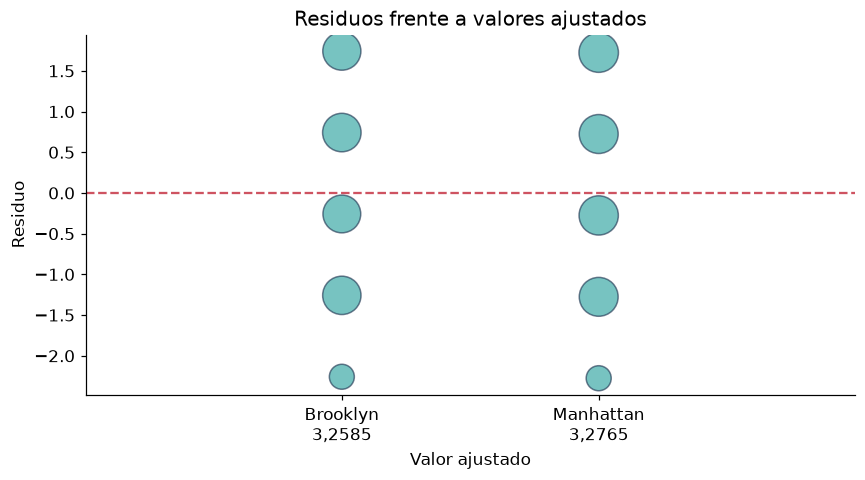

In [38]:
diag = pd.DataFrame({'ajustado': modelo.fittedvalues, 'residuo': modelo.resid})
diag = diag.groupby(['ajustado','residuo']).size().reset_index(name='anuncios')
fig, ax = plt.subplots(figsize=(8,4.5))
ax.scatter(diag.ajustado, diag.residuo, s=diag.anuncios/15,
           color='#1c9c99', alpha=.6, edgecolors='#182b49')
ax.axhline(0, color='#ce5361', ls='--')
ax.set(xlabel='Valor ajustado', ylabel='Residuo', title='Residuos frente a valores ajustados')
ax.set_xticks([mu_b,mu_m], [f'Brooklyn\n{numero(mu_b,4)}', f'Manhattan\n{numero(mu_m,4)}'])
ax.set_xlim(mu_b-.018,mu_m+.018)
fig.tight_layout()
plt.show()

**Interpretación.** Aparecen dos columnas y cinco niveles por columna, como corresponde a una respuesta discreta con cinco valores. Los residuos no forman una nube normal continua. La media residual dentro de cada distrito es cero por construcción del ajuste, lo que no demuestra una buena capacidad predictiva. La dispersión es grande respecto de la separación entre medias ajustadas. El gráfico respalda el bajo R² y la poca utilidad para predecir una nota individual. No permite verificar independencia. Usamos inferencia robusta y asintótica en lugar de justificarla con normalidad de los errores.

### 5.4 Limitaciones del modelo y del análisis
- Desconocemos la selección de anuncios y el mecanismo de notas faltantes. Los casos completos pueden estar sesgados.
- Un anfitrión puede tener varios anuncios y existir dependencia espacial. Los EE e IC calculados suponen independencia y podrían subestimar incertidumbre.
- Solo se comparan Manhattan y Brooklyn. No se controlan tipo de alojamiento, precio, localización precisa u otras características.
- La calificación es ordinal. Trabajar con medias supone interpretar los saltos entre categorías como comparables, igual que en E2.
- El modelo explica diferencias de medias, no la distribución completa de las notas ni una relación causal. La validación interna de bondad de ajuste no soluciona estas limitaciones.

## 6. Interpretación y conclusión integrada
La calificación media observada de Manhattan supera por aproximadamente **0,0181 puntos** a la de Brooklyn. Los IC percentiles al 95,4 % cuantifican la incertidumbre y acotan una diferencia de pocas centésimas. Reducir el semiancho en un 55 % exigiría cerca de 4,94 veces el tamaño actual bajo condiciones estables. Bajar la confianza produce intervalos más estrechos a costa de menor cobertura.

La validación interna de la distribución categórica no detecta incompatibilidad entre mitades. Esto evita una prueba circular del ajuste, pero no demuestra el modelo ni sus supuestos. Welch entrega evidencia limitada de una diferencia de medias al nivel fijado, mientras el contraste de notas 4–5 no detecta diferencia de proporciones. No hay contradicción porque los parámetros son distintos.

La regresión reproduce la diferencia de medias y tiene una capacidad explicativa y predictiva muy baja. El resultado central es una **diferencia pequeña**, cuya significancia estadística no implica una ventaja práctica importante ni causalidad.

## Referencias consultadas
Las decisiones del proyecto se basan en los dos archivos finales de E2 y en *Laboratorio 3 - Intervalos de Confianza y Test de Hipótesis*, INF280, 26 de octubre de 2026. Fuentes metodológicas primarias, consultadas el 28 de octubre de 2026:

1. [NIST: Chi-square goodness-of-fit](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35f.htm), conteos y ajuste de distribuciones discretas.
2. [NIST: Kolmogorov-Smirnov](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35g.htm), límites de la calibración continua y parámetros estimados.
3. [NIST: Anderson-Darling](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35e.htm), sensibilidad a colas y calibración específica.
4. [SciPy: chisquare](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chisquare.html), parámetros estimados y grados de libertad.
5. [SciPy: goodness_of_fit](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html), principio de recalibrar y reestimar parámetros por simulación. Nuestra implementación es propia para conteos discretos y dos mitades; no usamos directamente esa función para distribuciones continuas.
6. [SciPy: ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html), contraste de Welch.
7. [Statsmodels: HC3](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hc3.html), covarianza robusta para la regresión.